In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import seaborn as sns

pd.set_option('display.max_columns', 50) # tells pandas to display up to 50 columns when printing a DataFrame
pd.set_option('display.max_rows', 50)    # tells pandas to display up to 50 rows when printing a DataFrame


In [2]:
Directory = '/Users/josemenezes/Faculdade/Projetos/Projeto ML/Projeto-Machine-Learning/project/data/'

train_data = pd.read_csv(Directory + 'train.csv')
teste_data = pd.read_csv(Directory + 'test.csv', index_col='customer_id')
clients = pd.read_csv(Directory + 'clientes.csv', index_col='customer_id')
target = 'repeat_purchase_90d'

print('train data:', train_data.shape, '| test data:', teste_data.shape, '| clients data:', clients.shape)

train data: (6534, 39) | test data: (986, 37) | clients data: (1143, 12)


# Initial Data Cleaning

In [3]:
train_data.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [4]:
train_data.rename(columns={

    'Total a Pagar': 'total_due',
    'Total Bruto': 'total_gross', 
    'Total Liquido': 'total_net', 
    'Total Imp_': 'total_taxes', 
    'Total Portes': 'total_postage', 
    'Total Desc_ Global': 'total_global_discount', 
    'Total Desc_ Linha': 'total_line_discount', 
    'N_ Detalhes': 'number_of_items', 
    'Custo': 'cost'
    
}, inplace=True)

train_data['purchase_date'] = pd.to_datetime(train_data['purchase_date'], format='%Y-%m-%d') # convert the 'purchase_date' column to datetime format

## String column Levels

In [5]:
str_columns =['payment_type', 'salesperson', 'commercial_zone', 'transport_method',
             'warehouse', 'document_series', 'purchase_date']
str_df = []
for c in str_columns:
    str_df.append({"variable": c, "levels_train": train_data[c].nunique(),
                 "top_level_share_train": round(train_data[c].value_counts(normalize=True).iloc[0], 2),
    })
pd.DataFrame(str_df)

,variable,levels_train,top_level_share_train
0,payment_type,9,0.73
1,salesperson,9,0.65
2,commercial_zone,5,0.97
3,transport_method,80,0.18
4,warehouse,2,1.00
5,document_series,3,0.42
6,purchase_date,1492,0.01


# Target evaluation

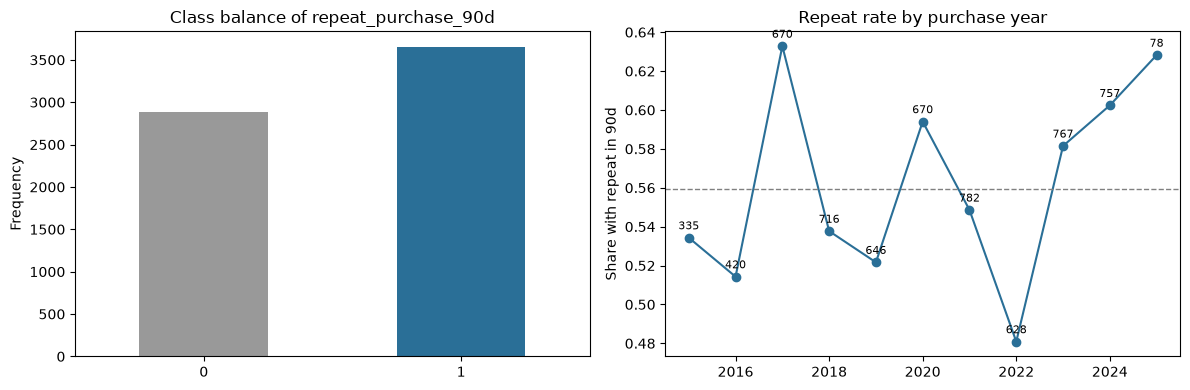

repeat_purchase_90d
1    0.56
0    0.44
Name: proportion, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

train_data[target].value_counts().sort_index().plot.bar(ax=ax[0], color=["#999999", "#2a6f97"])
ax[0].set_title("Class balance of repeat_purchase_90d")
ax[0].set_xlabel(""); ax[0].set_ylabel("Frequency"); ax[0].tick_params(axis="x", rotation=0)

yearly = train_data.groupby(train_data["purchase_date"].dt.year)[target].agg(['mean', 'size'])
ax[1].plot(yearly.index, yearly['mean'], marker='o', color="#2a6f97")
ax[1].axhline(train_data[target].mean(), ls="--", color='grey', lw=1)
ax[1].set_title("Repeat rate by purchase year")   
ax[1].set_ylabel("Share with repeat in 90d")
for yr, r in yearly.iterrows():
    ax[1].annotate(int(r['size']), (yr, r['mean']), textcoords="offset points", xytext=(0, 6),
                   ha="center", fontsize=8)
plt.tight_layout(); 
plt.show()

print(train_data[target].value_counts(normalize=True).round(2))

# Data exploration

In [7]:
train_data.columns

Index(['total_due', 'total_gross', 'total_net', 'total_taxes', 'total_postage',
       'total_global_discount', 'total_line_discount', 'cost',
       'number_of_items', 'invoice_count_current_purchase',
       'repeat_purchase_90d', 'days_since_previous_purchase',
       'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend',
       'prior_mean_purchase_value', 'prior_std_purchase_value',
       'prior_min_purchase_value', 'prior_max_purchase_value',
       'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d',
       'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d',
       'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id',
       'payment_type', 'salesperson', 'commercial_zone', 'transport_method',
       'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise'],
      dtype='str')

In [8]:
train_data.dtypes

total_due                                float64
total_gross                              float64
total_net                                float64
total_taxes                              float64
total_postage                            float64
total_global_discount                    float64
total_line_discount                      float64
cost                                     float64
number_of_items                          float64
invoice_count_current_purchase           float64
repeat_purchase_90d                        int64
days_since_previous_purchase             float64
customer_tenure_days                     float64
prior_purchase_count                     float64
prior_total_spend                        float64
prior_mean_purchase_value                float64
prior_std_purchase_value                 float64
prior_min_purchase_value                 float64
prior_max_purchase_value                 float64
prior_mean_gap_days                      float64
prior_std_gap_days  

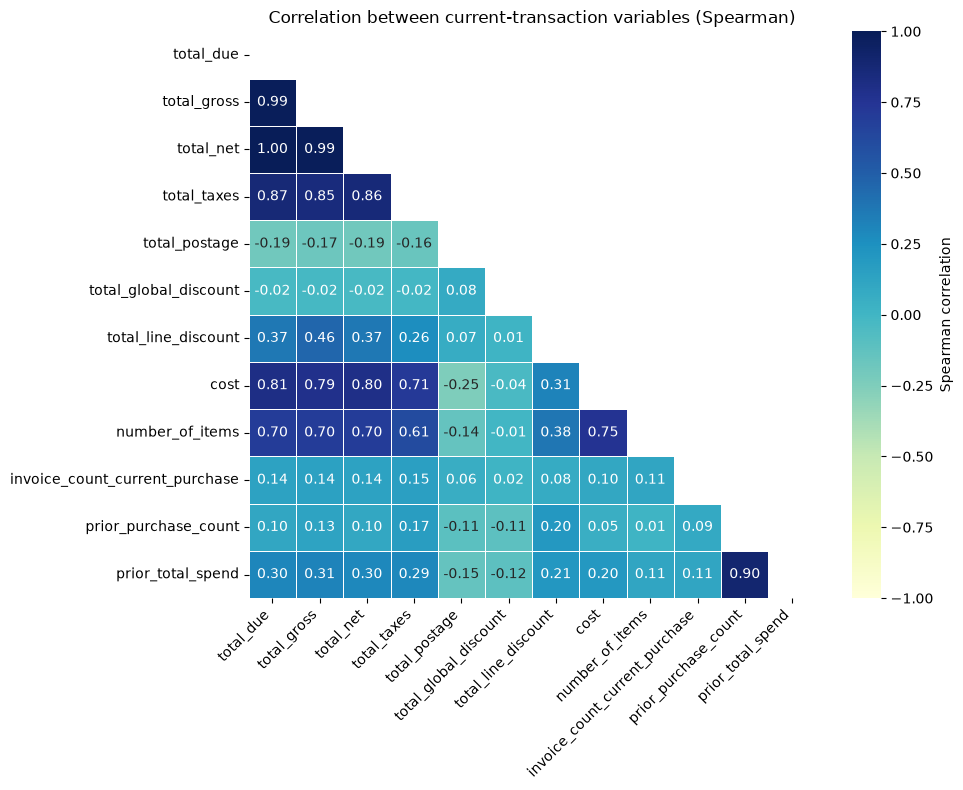

In [11]:
transaction_features = [
    'total_due', 'total_gross', 'total_net', 'total_taxes', 'total_postage',
       'total_global_discount', 'total_line_discount', 'cost',
       'number_of_items', 'invoice_count_current_purchase', 'prior_purchase_count', 'prior_total_spend'
]
corr = train_data[transaction_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='YlGnBu', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'})
plt.title('Correlation between current-transaction variables (Spearman)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Duplicates

In [ ]:
duplicates = train_data.duplicated().sum()
print(f"Number of duplicate rows in the training data: {duplicates}")
per_customer = train_data.groupby('customer_id').size()
print(f"Number of rows per customer:\n{per_customer.to_string()}")

Number of duplicate rows in the training data: 0
Number of rows per customer:
customer_id
103940    277
104399      1
104885      1
104924      1
105855      1
107064      1
109654      1
110878     15
111068      3
112516      1
112532     15
113110      1
116152      1
117553      1
119885     24
120418      1
120503     21
121562      2
122356     35
122573      3
128695     15
131189     22
131615      2
133497      1
136125      2
137103      2
137415     31
137493      5
138105      2
139739      4
140182     11
145109      1
146476     24
148011      3
149822      1
150345      7
151492     89
152297      4
160827      4
161053      5
165185      1
168942     42
169871      3
171254      1
172040      1
175701      7
175889      5
175924     29
177399      1
180223     43
180955      1
181367      5
181764     17
182819      4
184050     29
184947     12
185139      1
185502     13
185701      8
187401      2
189146     38
189957      2
191447      2
195425      5
196007      1


# Missing Values

In [ ]:
NA_train = train_data.isna().sum()
NA_Dataframe = pd.DataFrame({'Total NA' : NA_train, 'Total NA %': (100*(NA_train/len(train_data))).round(2)})
NA_Dataframe[NA_Dataframe['Total NA']>0].sort_values('Total NA', ascending=False)


,Total NA,Total NA %
prior_std_gap_days,1478,22.62
prior_mean_gap_days,1308,20.02
prior_std_purchase_value,1113,17.03
prior_mean_purchase_value,862,13.19
days_since_previous_purchase,861,13.18
prior_min_purchase_value,668,10.22
prior_max_purchase_value,668,10.22
transport_method,261,3.99
payment_type,260,3.98
spend_365d,260,3.98


In [ ]:
transaction_features = ['total_due', 'total_gross', 'total_net', 'total_taxes', 'total_postage',
                        'total_global_discount', 'total_line_discount', 'cost',
                        'number_of_items', 'invoice_count_current_purchase']
summary = train_data[transaction_features].describe().T
print(summary.round(2).to_string())

                                 count    mean      std   min     25%     50%      75%       max
total_due                       6469.0  925.56  1335.00  0.93  188.92  476.74  1087.67  22297.21
total_gross                     6469.0  886.15  1327.64  0.83  175.74  445.74  1036.70  21578.28
total_net                       6469.0  773.34  1136.36  0.76  154.38  389.91   903.37  18127.81
total_taxes                     6469.0  152.22   225.26  0.00   29.93   79.74   184.84   4169.40
total_postage                   6469.0    1.15     5.84  0.00    0.00    0.00     0.00    181.06
total_global_discount           6469.0    0.35     5.12  0.00    0.00    0.00     0.00    218.49
total_line_discount             6469.0  112.47   289.99  0.00    0.00   13.13    92.28   4103.44
cost                            6469.0  328.17   519.51  0.00   49.05  152.54   396.06   7427.40
number_of_items                 6469.0   21.52    27.71  1.00    4.00   11.00    29.00    423.00
invoice_count_current_purchase